# Assignment 8

Run the cells from top to bottom. Keep `Admission_Predict.csv` in the same folder as this notebook.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics 
import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score

In [2]:
data = pd.read_csv("admit.csv")
data.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65


In [3]:
print("Shape:", data.shape)
print("\nMissing values:")
print(data.isnull().sum())

Shape: (400, 9)

Missing values:
Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             3
Chance of Admit      0
dtype: int64


In [4]:
data = data.fillna(data.mode().iloc[0])
print(data.isnull().sum())

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64


In [5]:
new_data = data.drop(columns="Serial No.")

In [6]:
print(data.isnull().sum())

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64


In [7]:
print(data.columns)

Index(['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP',
       'LOR', 'CGPA', 'Research', 'Chance of Admit'],
      dtype='object')


In [8]:
new_data.dtypes

GRE Score              int64
TOEFL Score            int64
University Rating      int64
SOP                  float64
LOR                  float64
CGPA                 float64
Research             float64
Chance of Admit      float64
dtype: object

In [9]:
new_data["admitted"] = np.where(new_data["Chance of Admit"] <= 0.85, 0, 1)
new_data

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,admitted
0,337,118,4,4.5,4.5,9.65,1.0,0.92,1
1,324,107,4,4.0,4.5,8.87,1.0,0.76,0
2,316,104,3,3.0,3.5,8.00,1.0,0.72,0
3,322,110,3,3.5,2.5,8.67,1.0,0.80,0
4,314,103,2,2.0,3.0,8.21,0.0,0.65,0
...,...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0.82,0
396,325,107,3,3.0,3.5,9.11,1.0,0.84,0
397,330,116,4,5.0,4.5,9.45,1.0,0.91,1
398,312,103,3,3.5,4.0,8.78,0.0,0.67,0


In [10]:
data = new_data.drop(columns="Chance of Admit")

In [11]:
x = data[["GRE Score", "TOEFL Score", "University Rating", 
          "SOP", "LOR", "CGPA", "Research"]]
y = data["admitted"]

In [12]:
x_train, x_test, y_train, y_test = 
  train_test_split(x, y, test_size=0.20, random_state=0)

In [13]:
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (320, 7)
Testing data: (80, 7)


In [14]:
from sklearn.tree import DecisionTreeClassifier

In [15]:
dt = DecisionTreeClassifier(criterion="entropy")

In [16]:
dt.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy')

In [17]:
prediction = dt.predict(x_test)
prediction

array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0])

## Decision Tree – Evaluation

In [18]:
print("Confusion Matrix")
cm = confusion_matrix(y_test, prediction)
print(cm)

Confusion Matrix
[[61  3]
 [ 3 13]]


In [19]:
print("Accuracy Score")
acc = accuracy_score(y_test, prediction)
print(acc)

Accuracy Score
0.925


In [20]:
print("Precision")
precision = precision_score(y_test, prediction, average="weighted")
print(precision)

Precision
0.925


In [21]:
print("Recall")
recall = recall_score(y_test, prediction, average="weighted")
print(recall)

Recall
0.925


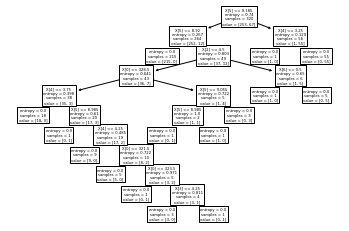

In [22]:
from sklearn.tree import plot_tree
tree = plot_tree(dt)

In [23]:
data

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,admitted
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0
396,325,107,3,3.0,3.5,9.11,1.0,0
397,330,116,4,5.0,4.5,9.45,1.0,1
398,312,103,3,3.5,4.0,8.78,0.0,0


In [24]:
print("Enter the details")
gre = float(input("GRE Score: "))
toefl = float(input("TOEFL Score: "))
rating = float(input("University Rating: "))
sop = float(input("SOP: "))
lor = float(input("LOR: "))
cgpa = float(input("CGPA: "))
research = float(input("Research: "))

Enter the details
GRE Score: 333
TOEFL Score: 110
University Rating: 3
SOP: 2
LOR: 4
CGPA: 9
Research: 1


In [25]:
user_input = [[gre, toefl, rating, sop, lor, cgpa, research]]
prediction = dt.predict(user_input)

if prediction[0] == 0:
    print("Student is Not admitted")
else:
    print("Student is admitted")

Student is Not admitted


In [26]:
from sklearn.naive_bayes import GaussianNB

In [28]:
nb = GaussianNB()
nb.fit(x_train, y_train)

GaussianNB()

In [29]:
nbpredict = nb.predict(x_test)
print(nbpredict)

[0 0 0 0 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0
 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 1 0 0 1 0 0 0 1 0 0
 1 0 0 0 1 0]


## Naive Bayes – Evaluation

In [30]:
print("Confusion Matrix")
cm = confusion_matrix(y_test, nbpredict)
print(cm)

Confusion Matrix
[[63  1]
 [ 3 13]]


In [31]:
print("Accuracy Score")
acc = accuracy_score(y_test, nbpredict)
print(acc)

Accuracy Score
0.95


In [32]:
print("Precision")
precision = precision_score(y_test, nbpredict, average="weighted")
print(precision)

Precision
0.9493506493506494


In [33]:
print("Recall")
recall = recall_score(y_test, nbpredict, average="weighted")
print(recall)

Recall
0.95


In [34]:
print("F1 Score")
f1 = f1_score(y_test, nbpredict, average="weighted")
print(f1)

F1 Score
0.9487179487179487


In [35]:
print("Enter the details")
gre = float(input("GRE Score: "))
toefl = float(input("TOEFL Score: "))
rating = float(input("University Rating: "))
sop = float(input("SOP: "))
lor = float(input("LOR: "))
cgpa = float(input("CGPA: "))
research = float(input("Research: "))

Enter the details
GRE Score: 334
TOEFL Score: 111
University Rating: 2
SOP: 4
LOR: 3
CGPA: 9.18
Research: 1


In [36]:
user_input = [[gre, toefl, rating, sop, lor, cgpa, research]]
nbpredict = nb.predict(user_input)

if nbpredict[0] == 0:
    print("Student is Not admitted")
else:
    print("Student is admitted")

Student is Not admitted
